# Customer Segmentation Analysis
----------------------------------

In [59]:
!mamba install pandas numpy matplotlib seaborn scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.515 seconds
All requested packages already installed.


In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

### Fetching data and performing initial inspection

In [61]:
from IPython.display import FileLink

# Generates a clickable download link in the output cell
FileLink("Ecommerce data.csv")

/drive/Ecommerce data.csv

In [62]:
file_path ="Ecommerce data.csv"
file_path

'Ecommerce data.csv'

In [63]:
df = pd.read_csv(file_path, encoding='unicode_escape')
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12-09-2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12-09-2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12-09-2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12-09-2011 12:50,4.15,12680.0,France


In [64]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 22.7 MB
None
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [65]:
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [66]:
df = df.dropna(subset=['CustomerID'])

In [67]:
df = df.drop_duplicates()

In [68]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', errors='coerce')

In [69]:
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')

In [70]:
df = df.dropna(subset=['InvoiceDate', 'Quantity', 'UnitPrice'])
df['TotalSpend'] = df['Quantity'] * df['UnitPrice']

### Descriptive statistics & RFM features

In [71]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [72]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency (days since last purchase)
    'InvoiceNo': 'nunique',                                  # Frequency (total orders)
    'TotalSpend': 'sum'                                      # Monetary / Customer Lifetime Value (CLV)
}).reset_index()

In [73]:
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

In [74]:
rfm['AvgPurchaseValue'] = rfm['Monetary'] / rfm['Frequency']

In [75]:
print("\n--- Customer Descriptive Statistics ---")
print(f"Average Purchase Value: ${rfm['AvgPurchaseValue'].mean():.2f}")
print(f"Average Purchase Frequency: {rfm['Frequency'].mean():.2f} orders")
print(f"Average Customer Lifetime Value (CLV): ${rfm['Monetary'].mean():.2f}")


--- Customer Descriptive Statistics ---
Average Purchase Value: $417.65
Average Purchase Frequency: 4.27 orders
Average Customer Lifetime Value (CLV): $2048.69


### Feature selection & standardisation

In [76]:
features = rfm[['Recency', 'Frequency', 'Monetary']]

In [77]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

### K-MEANS & ELBOW Method

In [78]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

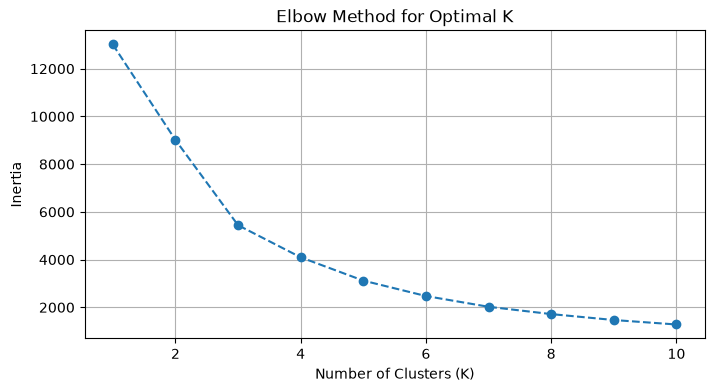

In [79]:
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [80]:
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(scaled_features)

###  Visualize clusters (SCATTER PLOTS)

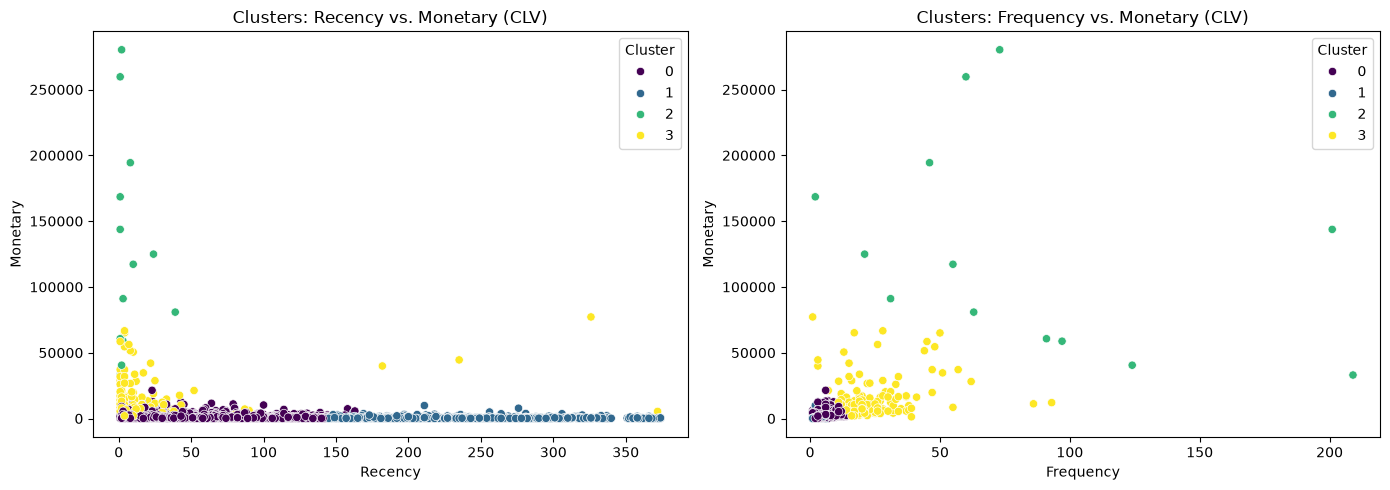

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Recency vs Monetary
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster', palette='viridis', ax=axes[0])
axes[0].set_title('Clusters: Recency vs. Monetary (CLV)')

# Plot 2: Frequency vs Monetary
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Cluster', palette='viridis', ax=axes[1])
axes[1].set_title('Clusters: Frequency vs. Monetary (CLV)')

plt.tight_layout()
plt.show()

### Cluster profiling

In [82]:
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'CustomerCount'}).round(2)

print("\n--- Cluster Profiles (Mean Values) ---")
print(cluster_profile)


--- Cluster Profiles (Mean Values) ---
         Recency  Frequency   Monetary  CustomerCount
Cluster                                              
0          43.70       3.68    1353.63           3054
1         248.08       1.55     478.85           1067
2           7.38      82.54  127187.96             13
3          15.50      22.33   12690.50            204


### BAR CHART: Customers per cluster

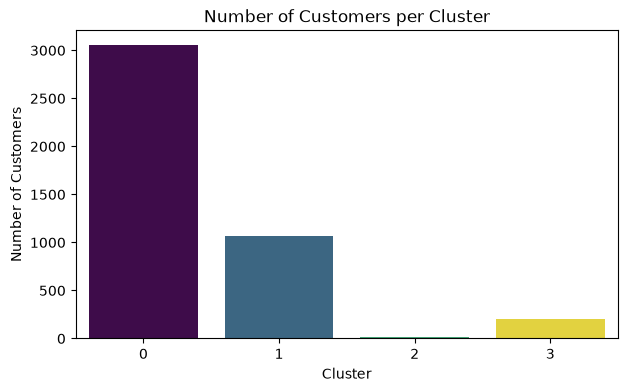

In [83]:
plt.figure(figsize=(7, 4))
sns.countplot(data=rfm, x='Cluster', hue='Cluster', palette='viridis', legend=False)
plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

### Insights section: what marketing action would you recommend for each segment?

#### 1.Champions (Best Customers): They buy often, spend a lot, and bought recently.

* Action: Give them VIP perks, early access to new items, and ask them to refer friends.

#### 2.Loyal Customers (Regulars): They buy consistently and spend a good amount.

* Action: Suggest similar products (upsell) and offer bundle deals so they buy more each time.

#### 3.New / Occasional Buyers: They bought recently, but only once or twice.

* Action: Send a welcome email and give a small coupon for their next order to bring them back.

#### 4.At-Risk / Lost Customers: They haven't bought anything in a long time.

* Action: Send a "We miss you!" email with a big limited-time discount to win them back.